# Break the Watermark! — V2 : classement équitable et explication des gains

**Objectif primaire : quelle attaque a le meilleur taux de suppression (ASR) pour un nombre identique de mots effectivement substitués ?**

**Objectif secondaire : expliquer le gain** en séparant le choix du pool, le classement, le choix du synonyme et la couverture des hybrides.

Le notebook conserve les statistiques et les substitutions WordNet des notebooks V1/V2/V3. Trois expériences sont distinguées :

1. **Global matched** : V1/V2/V3 et baselines avec le **même nombre exact de substitutions par texte**, budget plafonné par le plus petit pool (et par les deux supports). Pas de sélection des textes réussis seulement.
2. **Duel V2–V3** : comparaison appariée avec le budget commun aux seules méthodes V2 et V3 (sans le goulot d'étranglement V1), et **duel hybride V2–V3** sous un budget pairwise identique. Ce duel permet de départager les candidats sans confondre taux de remplacement et ASR.
3. **Diagnostics causaux** : hasard global vs hasard dans le pool, classement vs hasard dans le pool, synonymes guidés vs aléatoires, pool commun, support 1/2, recouvrement des positions et analyse des désaccords.

**Mode par défaut : pilote de 30 textes.** Après validation, `FAST_PILOT=False` et 10 splits 400/200. Les splits se chevauchent : les moyennes/écarts types sont descriptifs. Les tests appariés inférentiels sont faits uniquement sur le split de référence (42), à budget primaire déclaré avant le test final.

**Important :** le baseline MarkLLM original utilise un éditeur différent et un comptage approché des modifications ; il reste dans un rapport séparé de comparaison pratique. Un futur holdout de nouveaux prompts sera nécessaire pour toute conclusion finale indépendante.


## 0 — Préparation de l'environnement

Le runtime VS Code/Colab doit voir le **dossier du projet** (et ses modèles) : monter Drive ou cloner le dépôt si nécessaire. Installer les dépendances suivant l'environnement existant. **Ne pas remplacer la version de `transformers` déjà exigée par le dépôt.**

Sur Colab, le dossier `/content` est éphémère. Il faut **configurer `PERSISTENT_OUTPUT_ROOT` sur un dossier Drive monté** ; chaque checkpoint est écrit directement dans ce dossier. Sur Mac/local, vous pouvez laisser `None` si le projet vit dans un dossier persistant. Un export `.zip` final peut ensuite être téléchargé.

In [16]:
# Si certaines dépendances manquent (décommenter, lancer UNE fois):
# %pip install -q nltk numpy pandas scipy tqdm matplotlib nbformat
# %pip install -q markllm  # uniquement si le dépôt ne l'a pas déjà installé
# %pip install -q sentence-transformers  # pour l'évaluation sémantique optionnelle

# Colab uniquement, si le Drive doit être monté :
# from google.colab import drive
# drive.mount('/content/drive')

import os, re, sys, json, time, math, hashlib, random, tempfile, shutil, difflib, importlib.metadata
from pathlib import Path
from functools import lru_cache
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import nltk
from nltk.corpus import wordnet
from scipy.stats import binomtest
from scipy.integrate import trapezoid
from tqdm.auto import tqdm
from IPython.display import display
nltk.download('wordnet', quiet=True)
assert len(wordnet.synsets('important')) > 0
print('Environment ready | Python:', sys.version.split()[0])

Environment ready | Python: 3.12.0


## 1 — Configuration centrale

**Par défaut**, le notebook exécute un *petit pilote* sur 30 textes de test, afin de valider tous les composants et les sauvegardes. Puis passer à `FAST_PILOT=False` et utiliser une nouvelle sortie `full` (les checkpoints ne se mélangent jamais). Les dix splits se chevauchent : ne **pas** fusionner leurs lignes comme des observations indépendantes.

Le mode `final` exige un fichier de protocole figé et un jeu indépendant, et utilise **un seul** test final. Ne pas traiter le même texte comme plusieurs échantillons en raison de répétitions d'aléa.

In [17]:
# ================== MODIFIER CES PARAMÈTRES ==================
RUN_MODE = 'development'        # 'development' puis 'final'
FAST_PILOT = False               # mettre False pour vraie expérience
PROJECT_ROOT_OVERRIDE = None    # e.g. '/content/break-the-watermark'
PERSISTENT_OUTPUT_ROOT = None  # sur Colab: '/content/drive/MyDrive/TrustworthyAI/results_benchmark'
ALLOW_VOLATILE_OUTPUT = False   # déconseillé ; interdit pour le mode final

DEV_SPLIT_SEEDS = [42, 100, 101, 102, 103, 104, 105, 106, 107, 108]  # 10 splits 400/200 (pilot = 30 textes par split)
SUPPORTS = [1, 2]
RATIOS = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
PRIMARY_RATIO = 0.20           # seuil déclaré AVANT le test final
ALPHA = 0.5

INCLUDE_MARKLLM_ORIGINAL = True
STORE_ATTACKED_TEXT = True
SEMANTIC_EVAL = False            # passer à True après l'attaque (section 9)
SEMANTIC_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
SEMANTIC_MAX_PAIRS = 3000       # None pour les évaluer toutes
FREEZE_PROTOCOL_AFTER_DEVELOPMENT = False  # activer explicitement après sélection du protocole

# Nouvelles générations watermarked, JAMAIS utilisées dans le développement :
FINAL_WM_REL = 'results/final_holdout/watermarked.jsonl'
FINAL_NOWM_REL = 'results/final_holdout/unwatermarked.jsonl'  # optionnel; pas utilisé pour entraîner

WORD_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")
MAIN_MATCHED = ['random_wordnet_matched', 'v1_rank_matched', 'v2_rank_matched',
                'v2_pool_random_matched', 'v2_synonym_guided_matched',
                'v3_rank_matched', 'v3_pool_random_matched']
PAIR_MATCHED = ['v2_pair_rank', 'v3_pair_rank', 'v2_pair_hybrid', 'v3_pair_hybrid']
COMMON_MATCHED = ['random_common_pool', 'v1_common_rank', 'v2_common_rank', 'v3_common_rank']
NATIVE = ['v2_hybrid_native', 'v3_hybrid_native']
OFFICIAL = ['markllm_original_native'] if INCLUDE_MARKLLM_ORIGINAL else []
METHODS = MAIN_MATCHED + PAIR_MATCHED + COMMON_MATCHED + NATIVE + OFFICIAL
assert RUN_MODE in ('development','final')
assert all(0 < r <= 0.5 for r in RATIOS) and PRIMARY_RATIO in RATIOS
assert all(s >= 1 for s in SUPPORTS) and len(SUPPORTS) == len(set(SUPPORTS))

def find_project_root(start):
    choices = [start, *start.parents]
    if os.getenv('PROJECT_ROOT'):
        choices.insert(0, Path(os.getenv('PROJECT_ROOT')).expanduser())
    if PROJECT_ROOT_OVERRIDE:
        choices.insert(0, Path(PROJECT_ROOT_OVERRIDE).expanduser())
    for folder in choices:
        if (folder / 'src' / 'detection.py').is_file() and (folder / 'results' / 'Cleaned Data').is_dir():
            return folder.resolve()
    raise FileNotFoundError('Project missing: set PROJECT_ROOT_OVERRIDE to a folder with src/detection.py and results/Cleaned Data')

ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT / 'src'))
from detection import detect, load_detector, load_jsonl
import detection as detection_module

if PERSISTENT_OUTPUT_ROOT:
    BASE_OUTPUT = Path(PERSISTENT_OUTPUT_ROOT).expanduser()
else:
    BASE_OUTPUT = ROOT / 'results' / 'attacks' / 'fair_comparison_benchmark_v2'
if str(BASE_OUTPUT).startswith('/content/') and not str(BASE_OUTPUT).startswith('/content/drive/') and not ALLOW_VOLATILE_OUTPUT:
    raise RuntimeError('Colab /content is ephemeral! Set PERSISTENT_OUTPUT_ROOT to your mounted Google Drive folder.')
if RUN_MODE == 'final' and ALLOW_VOLATILE_OUTPUT:
    raise ValueError('Final evaluation must use persistent storage.')
BASE_OUTPUT.mkdir(parents=True, exist_ok=True)
RUN_TAG = f'{RUN_MODE}_' + ('pilot' if FAST_PILOT else 'full')
OUT_DIR = BASE_OUTPUT / RUN_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR = OUT_DIR / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PROTOCOL_LOCK = BASE_OUTPUT / 'frozen_protocol.json'

if RUN_MODE == 'final' and FAST_PILOT:
    raise ValueError('Set FAST_PILOT=False for final evaluation; pilot does not count as final evidence.')
if RUN_MODE == 'final' and not PROTOCOL_LOCK.exists():
    raise FileNotFoundError(f'No frozen protocol: {PROTOCOL_LOCK}. Freeze once in development before viewing holdout.')

print('ROOT:', ROOT, '| output:', OUT_DIR)
print('Mode:', RUN_MODE, '| pilot:', FAST_PILOT, '| methods:', len(METHODS))

ROOT: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking | output: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/fair_comparison_benchmark_v2/development_full
Mode: development | pilot: False | methods: 18


## 2 — Données, empreintes et isolation du test final

Les paires WM/NoWM sont alignées par prompt, comme dans vos notebooks. En développement : split stratifié **400 entraînement / 200 test** sur les 600 paires. En final : statistiques apprises sur les **600 paires de développement**, évaluées sur le nouveau jeu WM indépendant. Les réponses NoWM du holdout ne servent **jamais** à l'entraînement. Le détecteur est le même que dans `src/detection.py`.

In [18]:
def read_jsonl(path):
    return load_jsonl(path)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for part in iter(lambda: fh.read(1024 * 1024), b''):
            h.update(part)
    return h.hexdigest()

def text_hash(text):
    return hashlib.sha256(text.encode('utf-8')).hexdigest()

def prompt_key(s):
    return re.sub(r'\s+', ' ', s.strip()).casefold()

def data_group(row):
    return row.get('dataset_name', row.get('dataset','unknown')).split('_batch_')[0]

WM_PATH = ROOT / 'results' / 'Cleaned Data' / 'watermarked_600.jsonl'
NOWM_PATH = ROOT / 'results' / 'Cleaned Data' / 'unwatermarked_600.jsonl'
BASELINE_PATH = ROOT / 'results' / 'attacks' / 'baseline_original.jsonl'
wm = read_jsonl(WM_PATH)
no_wm = read_jsonl(NOWM_PATH)
assert len(wm) == len(no_wm) == 600, 'Expected original 600 paired examples'
assert all(w['prompt'] == n['prompt'] and w['completion'] and n['completion']
           for w,n in zip(wm,no_wm)), 'Paired data mismatch'
assert len({prompt_key(w['prompt']) for w in wm}) == 600, 'Duplicate dev prompts: inspect leakage before continuing'

groups = defaultdict(list)
for idx, row in enumerate(wm):
    groups[data_group(row)].append(idx)
assert sorted(map(len, groups.values())) == [200,200,200], 'Expected three datasets, 200 prompts each'

def make_split(seed):
    rng = random.Random(seed)
    train, test = [], []
    for j,(group,original_ids) in enumerate(sorted(groups.items())):
        ids = original_ids.copy()
        rng.shuffle(ids)
        n_train = 134 if j == 0 else 133
        train.extend(ids[:n_train]); test.extend(ids[n_train:])
    train,test = sorted(train),sorted(test)
    assert len(train)==400 and len(test)==200 and set(train).isdisjoint(test)
    return train,test

final_wm_path = ROOT / FINAL_WM_REL
final_no_wm_path = ROOT / FINAL_NOWM_REL
if RUN_MODE == 'final':
    if not final_wm_path.exists():
        raise FileNotFoundError(f'Final holdout missing: {final_wm_path}')
    test_wm = read_jsonl(final_wm_path)
    assert len(test_wm) >= 1 and all(row.get('prompt') and row.get('completion') for row in test_wm)
    final_prompts = [prompt_key(r['prompt']) for r in test_wm]
    assert len(final_prompts) == len(set(final_prompts)), 'Duplicate prompts in final holdout'
    overlap = set(final_prompts) & {prompt_key(row['prompt']) for row in wm}
    assert not overlap, f'Data leakage! {len(overlap)} final prompts already used in development'
    if final_no_wm_path.exists():
        holdout_nowm = read_jsonl(final_no_wm_path)
        assert len(holdout_nowm) == len(test_wm)
        assert all(a['prompt'] == b['prompt'] for a,b in zip(test_wm, holdout_nowm))
    ALL_RUN_SPLITS = [('final_holdout', list(range(600)), list(range(len(test_wm))))]
else:
    test_wm = wm
    ALL_RUN_SPLITS = [(str(s),*make_split(s)) for s in DEV_SPLIT_SEEDS]

if FAST_PILOT:
    assert RUN_MODE == 'development'
    mini = []
    for split_id, train, test in ALL_RUN_SPLITS:
        by_group = defaultdict(list)
        for i in test:
            by_group[data_group(wm[i])].append(i)
        mini_ids=[]
        for _, indices in sorted(by_group.items()):
            mini_ids.extend(indices[:10])
        mini.append((split_id,train,sorted(mini_ids)))
    ALL_RUN_SPLITS = mini

INPUT_HASHES = {str(WM_PATH.relative_to(ROOT)):sha256_file(WM_PATH),
                str(NOWM_PATH.relative_to(ROOT)):sha256_file(NOWM_PATH),
                'src/detection.py':sha256_file(ROOT/'src/detection.py')}
if BASELINE_PATH.exists(): INPUT_HASHES[str(BASELINE_PATH.relative_to(ROOT))] = sha256_file(BASELINE_PATH)
if RUN_MODE=='final':
    INPUT_HASHES[FINAL_WM_REL] = sha256_file(final_wm_path)
    if final_no_wm_path.exists(): INPUT_HASHES[FINAL_NOWM_REL] = sha256_file(final_no_wm_path)

print('Splits:',[(s,len(tr),len(te)) for s,tr,te in ALL_RUN_SPLITS])
print('Train sources only:', WM_PATH, NOWM_PATH)

Splits: [('42', 400, 200), ('100', 400, 200), ('101', 400, 200), ('102', 400, 200), ('103', 400, 200), ('104', 400, 200), ('105', 400, 200), ('106', 400, 200), ('107', 400, 200), ('108', 400, 200)]
Train sources only: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/Cleaned Data/watermarked_600.jsonl /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/Cleaned Data/unwatermarked_600.jsonl


## 3 — Détecteur et vérification du tokenizer

Le score token-bigramme V3 utilise une **retokenisation post-hoc** de la réponse : il ne récupère pas les états internes de génération par diffusion. Quand les offsets sont indisponibles, la localisation des tokens touchés par un mot est estimée par remplacement sentinelle, exactement comme V3.

In [19]:
tokenizer, detector = load_detector(ROOT)
try:
    probe = tokenizer('The model generates reliable answers.', add_special_tokens=False,
                      return_offsets_mapping=True)
    FAST_OFFSETS = (len(probe['input_ids']) == len(probe['offset_mapping']) and
                    any(int(b)>int(a) for a,b in probe['offset_mapping']))
except (TypeError, ValueError, KeyError, NotImplementedError):
    FAST_OFFSETS = False
ALIGNMENT_MODE = 'token_offsets' if FAST_OFFSETS else 'retokenized_difference_probe'
try: TRANSFORMERS_VERSION = importlib.metadata.version('transformers')
except importlib.metadata.PackageNotFoundError: TRANSFORMERS_VERSION = 'unknown'
TOKENIZER_SHA = hashlib.sha256(json.dumps(sorted(tokenizer.get_vocab().items()),ensure_ascii=False).encode()).hexdigest()
print('Tokenizer:',getattr(tokenizer,'name_or_path',type(tokenizer).__name__), '| alignment:',ALIGNMENT_MODE)
print('Transformers:',TRANSFORMERS_VERSION)

PROTOCOL = {
 'method_names':METHODS,
 'supports':SUPPORTS,
 'ratios':RATIOS,
 'primary_ratio':PRIMARY_RATIO,
 'alpha':ALPHA,
 'word_pattern':WORD_PATTERN.pattern,
 'alignment_mode':ALIGNMENT_MODE,
 'transformers_version':TRANSFORMERS_VERSION,
 'tokenizer_sha256':TOKENIZER_SHA,
 'detector_sha256':INPUT_HASHES['src/detection.py'],
 'detector_alpha':getattr(detection_module,'ALPHA',None),
 'development_input_hashes':{k:v for k,v in INPUT_HASHES.items() if 'final_holdout' not in k},
 'markllm_original_enabled':INCLUDE_MARKLLM_ORIGINAL,
 'markllm_version':(importlib.metadata.version('markllm') if INCLUDE_MARKLLM_ORIGINAL else None),
 'nltk_version':importlib.metadata.version('nltk'),
 'methodology': 'wordnet random replacements, exact V1/V2/V3 score functions, no detector queries for candidate selection',
}
if RUN_MODE=='final':
    frozen = json.loads(PROTOCOL_LOCK.read_text(encoding='utf-8'))
    assert frozen == PROTOCOL, 'FINAL PROTOCOL DIFFERS FROM FROZEN VERSION. Do not tune on final data.'
else:
    if PROTOCOL_LOCK.exists():
        print('Existing frozen protocol:',PROTOCOL_LOCK)
        if FREEZE_PROTOCOL_AFTER_DEVELOPMENT:
            assert json.loads(PROTOCOL_LOCK.read_text(encoding='utf-8')) == PROTOCOL, 'Existing freeze differs'

CONFIG = {'run_mode':RUN_MODE, 'fast_pilot':FAST_PILOT,
          'split_ids':[k for k,_,_ in ALL_RUN_SPLITS],
          'input_hashes':INPUT_HASHES,'protocol':PROTOCOL,
          'store_attacked_text':STORE_ATTACKED_TEXT}
config_path=OUT_DIR/'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text(encoding='utf-8')) == CONFIG, 'Change detected: use a new output folder, do not overwrite old checkpoints.'
else:
    config_path.write_text(json.dumps(CONFIG,indent=2,ensure_ascii=False),encoding='utf-8')
print('Reproducibility config checked:',config_path)

Tokenizer: GSAI-ML/LLaDA-8B-Instruct | alignment: token_offsets
Transformers: 5.22.1
Reproducibility config checked: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/fair_comparison_benchmark_v2/development_full/config.json


## 4 — Implémentations statistiques V1/V2/V3 (reprises des notebooks)

Les fonctions ci-dessous sont extraites des cellules originales V3 : score logarithmique lissé de fréquences WM/NoWM ; dictionnaire V1 ; bigrammes de mots V2 ; bigrammes d'IDs de tokens V3 ; gestion des offsets et des positions candidates. `MIN_SUPPORT=1` n'autorise **pas** à traiter un bigramme absent comme un score faible. Tous les modèles de scores utilisent uniquement les réponses du **train**.

In [20]:
def tokenize_words(text):
    return WORD_PATTERN.findall(text.lower())

def get_synonyms(word):
    candidates = set()
    for synset in wordnet.synsets(word):
        for lemma in synset.lemmas():
            candidate = lemma.name().lower()
            if candidate != word and re.fullmatch(r"[a-z]+", candidate):
                candidates.add(candidate)
    return tuple(sorted(candidates))

def smoothed_log_ratio(wm_counts, no_counts, alpha):
    vocabulary = set(wm_counts) | set(no_counts)
    v = len(vocabulary)
    if not v:
        raise ValueError("Empty training corpus")
    n_wm = sum(wm_counts.values())
    n_no = sum(no_counts.values())
    scores = {
        item: math.log(((wm_counts[item] + alpha) / (n_wm + alpha * v)) /
                       ((no_counts[item] + alpha) / (n_no + alpha * v)))
        for item in vocabulary
    }
    return scores

def learn_word_statistics(train_ids):
    wc_wm, wc_no, bc_wm, bc_no = Counter(), Counter(), Counter(), Counter()
    for idx in train_ids:
        wm_words = tokenize_words(wm[idx]["completion"])
        no_words = tokenize_words(no_wm[idx]["completion"])
        wc_wm.update(wm_words)
        wc_no.update(no_words)
        bc_wm.update(zip(wm_words[:-1], wm_words[1:]))
        bc_no.update(zip(no_words[:-1], no_words[1:]))
    return {
        "word_wm": wc_wm, "word_no": wc_no,
        "bigram_wm": bc_wm, "bigram_no": bc_no,
        "word_scores": smoothed_log_ratio(wc_wm, wc_no, ALPHA),
        "bigram_scores": smoothed_log_ratio(bc_wm, bc_no, ALPHA),
    }

def build_v1_dictionary(statistics, support):
    wm_counts = statistics["word_wm"]
    no_counts = statistics["word_no"]
    scores = statistics["word_scores"]
    dictionary = {}
    for word in sorted(scores):
        if wm_counts[word] + no_counts[word] < support or scores[word] <= 0:
            continue
        choices = [syn for syn in get_synonyms(word)
                   if syn in scores
                   and wm_counts[syn] + no_counts[syn] >= support
                   and scores[syn] < scores[word]]
        if choices:
            best = min(choices, key=lambda s: scores[s])
            dictionary[word] = {
                "replacement": best,
                "score": scores[word],
                "gain": scores[word] - scores[best],
            }
    return dictionary

def supported_bigram_score(statistics, bigram, support):
    n = statistics["bigram_wm"][bigram] + statistics["bigram_no"][bigram]
    return statistics["bigram_scores"].get(bigram) if n >= support else None

def collect_positions(text, statistics, support, v1_dict):
    matches = list(WORD_PATTERN.finditer(text.lower()))
    words = [m.group() for m in matches]
    v2, v1, all_wordnet = [], [], []
    for i, match in enumerate(matches):
        word = words[i]
        options = get_synonyms(word)
        if not options:
            continue
        base = {
            "word_index": i, "start": match.start(), "end": match.end(),
            "original": word, "prev": words[i - 1] if i else None,
            "next": words[i + 1] if i + 1 < len(words) else None,
        }
        all_wordnet.append(base)
        if word in v1_dict:
            v1.append({**base, "score_v1": v1_dict[word]["score"]})
        local_scores = []
        if i:
            score = supported_bigram_score(statistics, (words[i - 1], word), support)
            if score is not None:
                local_scores.append(score)
        if i + 1 < len(words):
            score = supported_bigram_score(statistics, (word, words[i + 1]), support)
            if score is not None:
                local_scores.append(score)
        s = sum(local_scores)
        if local_scores and s > 0:
            v2.append({**base, "score_sum": s,
                       "score_max": max(local_scores),
                       "n_observed_contexts": len(local_scores)})
    v2.sort(key=lambda p: -p["score_sum"])  # Python stable sort = tie by text order
    v1.sort(key=lambda p: -p["score_v1"])
    return len(matches), v2, v1, all_wordnet

def tokenize_ids(text):
    return tuple(int(v) for v in tokenizer(text, add_special_tokens=False)["input_ids"])

def token_bigram_counter(ids):
    return Counter(zip(ids[:-1], ids[1:]))

def learn_statistics(train_ids):
    stats = learn_word_statistics(train_ids)
    token_wm, token_no = Counter(), Counter()
    for idx in train_ids:
        token_wm.update(token_bigram_counter(tokenize_ids(wm[idx]["completion"])))
        token_no.update(token_bigram_counter(tokenize_ids(no_wm[idx]["completion"])))
    stats.update({
        "token_bigram_wm": token_wm,
        "token_bigram_no": token_no,
        "token_bigram_scores": smoothed_log_ratio(token_wm, token_no, ALPHA),
    })
    return stats

def supported_token_bigram_score(stats, pair, support):
    count = stats["token_bigram_wm"][pair] + stats["token_bigram_no"][pair]
    return stats["token_bigram_scores"].get(pair) if count >= support else None

def stable_int(*parts):
    blob = "::".join(map(str, parts)).encode("utf-8")
    return int.from_bytes(hashlib.blake2b(blob, digest_size=8).digest(), "big")

def differing_token_span(old_ids, new_ids):
    """Smallest changed interval in each token sequence, found via shared prefix/suffix."""
    pre = 0
    while pre < min(len(old_ids), len(new_ids)) and old_ids[pre] == new_ids[pre]:
        pre += 1
    suf = 0
    while (suf < len(old_ids) - pre and suf < len(new_ids) - pre and
           old_ids[len(old_ids) - 1 - suf] == new_ids[len(new_ids) - 1 - suf]):
        suf += 1
    return pre, len(old_ids) - suf, len(new_ids) - suf

def touching_pair_indices(n_ids, start_token, end_token_exclusive):
    """Pair index j refers to IDs[j], IDs[j+1]; include both boundary edges."""
    if n_ids < 2:
        return ()
    # Works even if a changed segment becomes zero tokens.
    left = max(0, start_token - 1)
    right = min(n_ids - 2, end_token_exclusive)
    return tuple(range(left, right + 1)) if left <= right else ()

def token_edges_for_words(text, matches, ids):
    """Word -> affected token-pair indices, using full-completion tokenization."""
    if FAST_OFFSETS:
        batch = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
        offsets = [(int(a), int(b)) for a, b in batch["offset_mapping"]]
        assert tuple(int(t) for t in batch["input_ids"]) == ids
        assert len(offsets) == len(ids)
        output = []
        for match in matches:
            inside = [i for i, (a, b) in enumerate(offsets)
                      if a < b and a < match.end() and b > match.start()]
            if inside:
                output.append(touching_pair_indices(len(ids), min(inside), max(inside) + 1))
            else:
                # Rare offset anomaly: fall back locally instead of silently dropping a word.
                output.append(_probe_word_edges(text, match, ids))
        return output
    return [_probe_word_edges(text, match, ids) for match in matches]

def _probe_word_edges(text, match, ids):
    """No offsets: replace ONE span with a sentinel and retokenize the full completion."""
    probed = text[:match.start()] + "uniquexyzprobe" + text[match.end():]
    probe_ids = tokenize_ids(probed)
    pre, end_old, _ = differing_token_span(ids, probe_ids)
    return touching_pair_indices(len(ids), pre, end_old)

def collect_all_positions(text, stats, support, v1_dict):
    # V1/V2 logic below is IDENTICAL to V2's collect_positions.
    n_words, v2, v1, all_wordnet = collect_positions(text, stats, support, v1_dict)
    matches = list(WORD_PATTERN.finditer(text.lower()))
    ids = tokenize_ids(text)
    edges_by_word = token_edges_for_words(text, matches, ids)
    v3 = []
    n_known_pairs = 0
    n_local_pairs = 0
    for position in all_wordnet:
        j = position["word_index"]
        edges = edges_by_word[j]
        values = [supported_token_bigram_score(stats, (ids[e], ids[e + 1]), support)
                  for e in edges]
        known = [float(value) for value in values if value is not None]
        n_known_pairs += len(known)
        n_local_pairs += len(values)
        if known and sum(known) > 0:
            v3.append({**position, "score_sum": sum(known),
                       "score_mean": float(np.mean(known)), "score_max": max(known),
                       "n_supported_token_pairs": len(known),
                       "n_touching_token_pairs": len(edges)})
    v3.sort(key=lambda p: -p["score_sum"])
    v2_ix = {p["word_index"] for p in v2}
    v1_ix = {p["word_index"] for p in v1}
    common_ix = {p["word_index"] for p in v3} & v2_ix & v1_ix
    return {
        "n_words": n_words, "n_tokens": len(ids), "v3": v3,
        "v2": v2, "v1": v1, "wordnet": all_wordnet,
        "common_indices": common_ix,
        "n_covered_union": len({p["word_index"] for p in (v3 + v2 + v1)}),
        "n_supported_local_pairs": n_known_pairs, "n_local_pairs": n_local_pairs,
        "original_token_ids": ids,
    }

### 4.1 — Vérification croisée optionnelle avec les anciens checkpoints V3

Si vous avez conservé les checkpoints du notebook `stealing_guided_v3`, nous comparons les tailles des pools des premières réponses du split 42, support 2. Cela sert de test de non-régression : si les implémentations ne donnent plus les mêmes ensembles éligibles, il faut résoudre le problème avant d'interpréter le benchmark.

In [21]:
OLD_V3_REFERENCE=(ROOT/'results'/'attacks'/'stealing_guided_v3_token_bigram'/'checkpoints'/'support_2'/'split_42'/'ratio_0.1.jsonl')
if RUN_MODE=='development' and 2 in SUPPORTS and OLD_V3_REFERENCE.exists():
    _train,_test=make_split(42)
    _stats=learn_statistics(_train)
    _dictionary=build_v1_dictionary(_stats,2)
    _lookup={(int(r['idx']),r['method']):r for r in read_jsonl(OLD_V3_REFERENCE)}
    for _idx in _test[:5]:
        _ctx=collect_all_positions(wm[_idx]['completion'],_stats,2,_dictionary)
        _ref=_lookup[(_idx,'v3_sum_random')]
        assert len(_ctx['v1'])==_ref['n_eligible_v1']
        assert len(_ctx['v2'])==_ref['n_eligible_v2']
        assert len(_ctx['v3'])==_ref['n_eligible_v3']
    print('V3 checkpoint cross-check PASS (5 examples, support 2)')
else:
    print('Optional cross-notebook check skipped (V3 checkpoint absent or final mode).')

V3 checkpoint cross-check PASS (5 examples, support 2)


## 5 — Substitutions originales et construction des variantes du benchmark

Les synonymes aléatoires utilisent le même `stable_int("syn", split_seed, ratio_index, idx, word_index)` que V2/V3. Un mot donné reçoit donc **le même synonyme** dans les comparaisons random, ce qui isole le choix des positions. `v2_synonym_guided_matched` utilise exactement la fonction de choix par bigrammes de mots de V2. Les variantes *native* remplissent le budget avec les pools V2→V1 ou V3→V2→V1.

In [22]:
def synonym_random(position, seed, ratio_index, idx):
    options = get_synonyms(position["original"])
    assert options
    k = stable_int("syn", seed, ratio_index, idx, position["word_index"]) % len(options)
    return options[k]

def case_match(original_surface, replacement):
    if original_surface.isupper():
        return replacement.upper()
    if original_surface.istitle():
        return replacement.capitalize()
    return replacement

def replace_one(text, position, replacement):
    a, b = position["start"], position["end"]
    surface = text[a:b]
    actual = case_match(surface, replacement)
    assert actual.lower() != surface.lower()
    return text[:a] + actual + text[b:]

def apply_substitutions(text, positions, replacements):
    assert len(positions) == len(replacements)
    attacked = text
    for position, synonym in sorted(zip(positions, replacements),
                                    key=lambda pair: pair[0]["start"], reverse=True):
        attacked = replace_one(attacked, position, synonym)
    return attacked

def sample_positions(candidates, n, *seed_parts):
    if not n:
        return []
    return random.Random(stable_int("positions", *seed_parts)).sample(candidates, n)

def synonym_guided_v2(position, statistics, support, split_seed, ratio_index, idx):
    original = position["original"]
    best_options = []
    # Evaluate locally in the original text's immediate word context.
    contexts_original = []
    if position["prev"] is not None:
        contexts_original.append((position["prev"], original))
    if position["next"] is not None:
        contexts_original.append((original, position["next"]))
    original_score = sum(
        supported_bigram_score(statistics, pair, support) or 0.0
        for pair in contexts_original
    )
    for syn in get_synonyms(original):
        new_pairs = []
        if position["prev"] is not None:
            new_pairs.append((position["prev"], syn))
        if position["next"] is not None:
            new_pairs.append((syn, position["next"]))
        if not new_pairs:
            continue
        new_scores = [supported_bigram_score(statistics, b, support) for b in new_pairs]
        # An unseen context is UNKNOWN, not a guaranteed reduction in watermark signal.
        if any(score is None for score in new_scores):
            continue
        score = sum(new_scores)
        if score < original_score:
            best_options.append((score, syn))
    if best_options:
        return min(best_options)[1], True  # statistically supported guided replacement
    return synonym_random(position, split_seed, ratio_index, idx), False

In [23]:
def select_methods(ctx, stats, support, split_seed, ratio_index, idx, matched_n, common_n):
    target = round(ctx['n_words'] * RATIOS[ratio_index])
    common_ix = ctx['common_indices']
    cv1 = [p for p in ctx['v1'] if p['word_index'] in common_ix]
    cv2 = [p for p in ctx['v2'] if p['word_index'] in common_ix]
    cv3 = [p for p in ctx['v3'] if p['word_index'] in common_ix]
    hybrid2 = list(ctx['v2'][:target]); used2={p['word_index'] for p in hybrid2}
    for p in ctx['v1']:
        if len(hybrid2)>=target: break
        if p['word_index'] not in used2:
            hybrid2.append(p); used2.add(p['word_index'])
    hybrid3 = list(ctx['v3'][:target]); used3={p['word_index'] for p in hybrid3}
    for pool in (ctx['v2'],ctx['v1']):
        for p in pool:
            if len(hybrid3)>=target: break
            if p['word_index'] not in used3:
                hybrid3.append(p); used3.add(p['word_index'])
    pair_rank_n = min(target, len(ctx['v2']), len(ctx['v3']))
    pair_hybrid_n = min(target, len(hybrid2), len(hybrid3))
    choices = {
        'random_wordnet_matched':sample_positions(ctx['wordnet'],matched_n,split_seed,ratio_index,idx,'wordnet_global'),
        'v1_rank_matched':ctx['v1'][:matched_n],
        'v2_rank_matched':ctx['v2'][:matched_n],
        'v2_pool_random_matched':sample_positions(ctx['v2'],matched_n,split_seed,ratio_index,idx,'v2_pool'),
        'v2_synonym_guided_matched':ctx['v2'][:matched_n],
        'v3_rank_matched':ctx['v3'][:matched_n],
        'v3_pool_random_matched':sample_positions(ctx['v3'],matched_n,split_seed,ratio_index,idx,'v3_pool'),
        'v2_pair_rank': ctx['v2'][:pair_rank_n],
        'v3_pair_rank': ctx['v3'][:pair_rank_n],
        'v2_pair_hybrid': hybrid2[:pair_hybrid_n],
        'v3_pair_hybrid': hybrid3[:pair_hybrid_n],
        'random_common_pool':sample_positions(cv3,common_n,split_seed,ratio_index,idx,'common'),
        'v1_common_rank':cv1[:common_n],
        'v2_common_rank':cv2[:common_n],
        'v3_common_rank':cv3[:common_n],
        'v2_hybrid_native':hybrid2,
        'v3_hybrid_native':hybrid3,
    }
    assert len({len(choices[m]) for m in MAIN_MATCHED}) == 1
    assert len(choices['v2_pair_rank']) == len(choices['v3_pair_rank'])
    assert len(choices['v2_pair_hybrid']) == len(choices['v3_pair_hybrid'])
    assert len({len(choices[m]) for m in COMMON_MATCHED}) == 1
    assert len(choices['v2_hybrid_native']) <= target
    assert len(choices['v3_hybrid_native']) <= target
    assert len({p['word_index'] for p in choices['v3_hybrid_native']}) == len(choices['v3_hybrid_native'])
    return target, choices

def make_text_variant(original, positions, method, stats, support, seed, ri, idx):
    replacements=[]; n_guided=0
    for pos in positions:
        if method=='v2_synonym_guided_matched':
            repl,genuine=synonym_guided_v2(pos,stats,support,seed,ri,idx)
            n_guided += int(genuine)
        else:
            repl=synonym_random(pos,seed,ri,idx)
        replacements.append(repl)
    attacked=apply_substitutions(original,positions,replacements)
    assert (original!=attacked)==bool(positions)
    return {'attacked':attacked,'n_replaced':len(positions),'n_guided':n_guided,
            'replacement_pairs':[{'word_index':p['word_index'],'original':p['original'],
                                  'replacement':repl} for p,repl in zip(positions,replacements)],
            'word_indices':[p['word_index'] for p in positions]}

def word_edit_proxy(original,attacked):
    a=WORD_PATTERN.findall(original.lower())
    b=WORD_PATTERN.findall(attacked.lower())
    distance=0
    for operation,i0,i1,j0,j1 in difflib.SequenceMatcher(a=a,b=b,autojunk=False).get_opcodes():
        if operation=='replace':distance+=max(i1-i0,j1-j0)
        elif operation=='delete':distance+=(i1-i0)
        elif operation=='insert':distance+=(j1-j0)
    return distance,len(a)

if INCLUDE_MARKLLM_ORIGINAL:
    try:
        from markllm.evaluation.tools.text_editor import SynonymSubstitution
        MARKLLM_VERSION=importlib.metadata.version('markllm')
    except (ImportError,ModuleNotFoundError,importlib.metadata.PackageNotFoundError) as e:
        raise RuntimeError('Official 05 baseline requires the SAME MarkLLM installation as your original notebook. Install repository dependencies.') from e
    markllm_editors={r:SynonymSubstitution(ratio=r) for r in RATIOS}
    print('Original 05 baseline: MarkLLM', MARKLLM_VERSION)
else:
    print('Warning: original 05 baseline disabled; no scientific comparison to the paper baseline.')

Original 05 baseline: MarkLLM 0.1.5


[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/paulmicheli/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/paulmicheli/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/paulmicheli/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/paulmicheli/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/paulmicheli/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/paulmicheli/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/paulmicheli/nltk_data...
[nltk_data]   Package wordnet is already up-t

## 6 — Détection, traçabilité et checkpoints

Le système détecte **uniquement** les textes initialement détectés pour le calcul ASR, comme dans vos notebooks. Pour éviter les pertes sur Colab : les résultats de détection sont écrits dans une **cache persistante append-only** dès chaque nouvelle requête, et chaque couple `(split, support, ratio)` dans un checkpoint JSONL écrit atomiquement. Les empreintes des entrées et du détecteur sont vérifiées avant de reprendre.

In [24]:
BASELINE_ROWS = read_jsonl(BASELINE_PATH) if BASELINE_PATH.exists() else None
BASELINE_BY_IDX = {int(r['idx']):r for r in BASELINE_ROWS} if BASELINE_ROWS else {}
if RUN_MODE=='development' and BASELINE_ROWS:
    assert len(BASELINE_BY_IDX)==600
    for idx in range(600):
        assert BASELINE_BY_IDX[idx]['prompt']==wm[idx]['prompt']

CACHE_FILE = OUT_DIR / 'detector_cache.jsonl'
DETECTION_CACHE={}
if CACHE_FILE.exists():
    for row in read_jsonl(CACHE_FILE):
        old=DETECTION_CACHE.get(row['sha256'])
        if old is not None: assert old==row, 'Detector cache collision or conflicting repeated result'
        DETECTION_CACHE[row['sha256']]=row
print('Resumed',len(DETECTION_CACHE),'cached detection records')

def detect_persistent(text):
    key=text_hash(text)
    if key not in DETECTION_CACHE:
        det=detect(text,tokenizer,detector)
        record={'sha256':key,'detected':bool(det['detected']),
                'p_value':float(det['p_value']),
                'green_fraction':float(det['green_fraction']) if det.get('green_fraction') is not None else None,
                'n_scored':int(det['n_scored']) if det.get('n_scored') is not None else None}
        assert 0 <= record['p_value'] <= 1 and math.isfinite(record['p_value'])
        with CACHE_FILE.open('a',encoding='utf-8') as fh:
            fh.write(json.dumps(record,ensure_ascii=False,allow_nan=False)+'\n')
        DETECTION_CACHE[key]=record
    return DETECTION_CACHE[key]

def original_detection(idx):
    text = test_wm[idx]['completion']
    if RUN_MODE=='development' and idx in BASELINE_BY_IDX:
        original = BASELINE_BY_IDX[idx]
        return {'detected':bool(original['detected']),'p_value':float(original['p_value'])}
    return detect_persistent(text)

# IMPORTANT: small recheck to catch mismatch of detector configuration / cached baseline.
if RUN_MODE=='development' and BASELINE_ROWS:
    for idx in [0,200,400]:
        observed=detect_persistent(wm[idx]['completion'])
        expected=original_detection(idx)
        assert observed['detected']==expected['detected'], f'Baseline-detector mismatch at idx={idx}'
        assert abs(observed['p_value']-expected['p_value']) < 1e-8, f'Baseline-detector mismatch at idx={idx}'
print('Original detector check OK')

# Never combine a newly changed config with old checkpoints.
def checkpoint_file(split_id,support,ratio):
    return CHECKPOINT_DIR / f'split_{split_id}' / f'support_{support}' / f'ratio_{ratio:.2f}.jsonl'

def save_atomic_jsonl(path,rows):
    path.parent.mkdir(parents=True,exist_ok=True)
    if path.exists(): raise FileExistsError(f'Refusing to overwrite existing checkpoint: {path}')
    with tempfile.NamedTemporaryFile(mode='w',encoding='utf-8',prefix='.tmp_',suffix='.jsonl',
                                     dir=path.parent,delete=False) as fh:
        tmp=Path(fh.name)
        try:
            for item in rows:
                fh.write(json.dumps(item,ensure_ascii=False,allow_nan=False)+'\n')
        except BaseException:
            tmp.unlink(missing_ok=True); raise
    if path.exists(): tmp.unlink(missing_ok=True); raise FileExistsError(path)
    tmp.replace(path)

def validate_rows(rows,split_id,support,ratio,test_ids):
    expected={(idx,method) for idx in test_ids for method in (MAIN_MATCHED+PAIR_MATCHED+COMMON_MATCHED+NATIVE+
            (OFFICIAL if support==SUPPORTS[0] else []))}
    received={(int(r['idx']),r['method']) for r in rows}
    assert len(rows)==len(expected) and received==expected, 'Checkpoint key mismatch'
    for r in rows:
        assert r['split_id']==split_id and r['support']==support and r['ratio']==ratio
        assert 0<=r['n_replaced']<=r['target'] or r['method']=='markllm_original_native'
        assert (r['detected'] is None)==(not r['original_detected'])
    for idx in test_ids:
        part={r['method']:r for r in rows if r['idx']==idx}
        assert len({part[m]['n_replaced'] for m in MAIN_MATCHED})==1
        assert len({part[m]['n_replaced'] for m in COMMON_MATCHED})==1
        assert part['v2_pair_rank']['n_replaced']==part['v3_pair_rank']['n_replaced']
        assert part['v2_pair_hybrid']['n_replaced']==part['v3_pair_hybrid']['n_replaced']
    return True

Resumed 0 cached detection records
Original detector check OK


## 7 — Exécution des attaques (avec reprise automatique)

- Dans la comparaison **matched**, le budget par texte est `min(target, tailles des pools V1/V2/V3 pour tous les supports activés)`. Il est donc identique entre méthodes **et** entre supports.
- Dans la comparaison **common**, le même pool de positions existe pour V1, V2 et V3, mais **leurs classements restent différents**. Le budget est encore borné par la taille de l'intersection.
- Dans la comparaison **native**, chaque hybride remplit son budget jusqu'à épuisement des pools; on rapporte le taux *réel*.
- Pour MarkLLM original, `n_replaced` est un **proxy d'alignement de mots** (via `difflib`), **pas** la mesure interne des substitutions de MarkLLM. Les comparaisons strictes se font avec `random_wordnet_matched`.

La première exécution peut être coûteuse (chargement modèle, WordNet, nombreuses requêtes au détecteur). Relancer reprend les checkpoints validés.

In [25]:
start=time.perf_counter()
for split_id, train_ids, test_ids in ALL_RUN_SPLITS:
    if RUN_MODE=='final':
        assert train_ids==list(range(600)), 'Holdout is not training data'
    print(f'\nSPLIT {split_id}: train={len(train_ids)}, test={len(test_ids)}')
    stats=learn_statistics(train_ids)
    dictionaries={s:build_v1_dictionary(stats,s) for s in SUPPORTS}
    pending={(s,r) for s in SUPPORTS for r in RATIOS
             if not checkpoint_file(split_id,s,r).exists()}
    for s in SUPPORTS:
        for r in RATIOS:
            path=checkpoint_file(split_id,s,r)
            if path.exists():
                validate_rows(read_jsonl(path),split_id,s,r,test_ids)
    if not pending:
        print('All checkpoints already completed');continue
    batches={(s,r):[] for s,r in pending}
    for idx in tqdm(test_ids,desc=f'split {split_id}'):
        original=test_wm[idx]['completion']
        baseline=original_detection(idx)
        # The FULL collection is computed independently for each support using identical trained stats.
        contexts={s:collect_all_positions(original,stats,s,dictionaries[s]) for s in SUPPORTS}
        assert len({contexts[s]['n_words'] for s in SUPPORTS})==1
        for ri,ratio in enumerate(RATIOS):
            target=round(contexts[SUPPORTS[0]]['n_words']*ratio)
            global_match=min([target]+[len(contexts[s][k]) for s in SUPPORTS for k in ('v1','v2','v3')])
            global_common=min([target]+[len(contexts[s]['common_indices']) for s in SUPPORTS])
            for support in SUPPORTS:
                if (support,ratio) not in pending: continue
                ctx=contexts[support]
                _, choices=select_methods(ctx,stats,support,split_id,ri,idx,global_match,global_common)
                assert len(choices['v2_rank_matched'])==global_match
                assert len(choices['v3_rank_matched'])==global_match
                for method, positions in choices.items():
                    variant=make_text_variant(original,positions,method,stats,support,split_id,ri,idx)
                    attacked=variant['attacked']
                    det=detect_persistent(attacked) if baseline['detected'] else None
                    nr=variant['n_replaced']; nwords=ctx['n_words']
                    assert nr <= target and len(variant['word_indices']) == len(set(variant['word_indices']))
                    row={
                        'split_id':split_id,'idx':idx,'dataset':data_group(test_wm[idx]),
                        'method':method,'support':support,'ratio':ratio,
                        'original_detected':bool(baseline['detected']),
                        'original_p_value':float(baseline['p_value']),
                        'detected':det['detected'] if det else None,
                        'p_value':det['p_value'] if det else None,
                        'n_words':nwords,'target':target,'matched_budget':global_match,
                        'common_budget':global_common,'n_replaced':nr,
                        'actual_edit_ratio':nr/nwords if nwords else 0.0,
                        'n_guided':variant['n_guided'],
                        'selected_indices':variant['word_indices'],
                        'replacement_pairs':variant['replacement_pairs'],
                        'n_eligible_v1':len(ctx['v1']),
                        'n_eligible_v2':len(ctx['v2']),
                        'n_eligible_v3':len(ctx['v3']),
                        'n_eligible_wordnet':len(ctx['wordnet']),
                        'n_eligible_common':len(ctx['common_indices']),
                        'n_eligible_union':ctx['n_covered_union'],
                        'attacked_sha256':text_hash(attacked),
                        'count_type':'exact_word_substitutions',
                    }
                    if STORE_ATTACKED_TEXT:
                        row.update({'original':original,'attacked':attacked})
                    batches[(support,ratio)].append(row)
                # Original 05, same seed convention as notebook 05, separately from matched pool.
                if INCLUDE_MARKLLM_ORIGINAL and support==SUPPORTS[0]:
                    random.seed(42+idx)
                    attacked=markllm_editors[ratio].edit(original)
                    diff_count,nwords=word_edit_proxy(original,attacked)
                    det=detect_persistent(attacked) if baseline['detected'] else None
                    row={
                        'split_id':split_id,'idx':idx,'dataset':data_group(test_wm[idx]),
                        'method':'markllm_original_native','support':support,'ratio':ratio,
                        'original_detected':bool(baseline['detected']),
                        'original_p_value':float(baseline['p_value']),
                        'detected':det['detected'] if det else None,
                        'p_value':det['p_value'] if det else None,
                        'n_words':nwords,'target':int(ratio*nwords),
                        'matched_budget':global_match,'common_budget':global_common,
                        'n_replaced':diff_count,
                        'actual_edit_ratio':diff_count/nwords if nwords else 0.0,
                        'n_guided':0,
                        'selected_indices':None,'replacement_pairs':None,
                        'n_eligible_v1':len(ctx['v1']),
                        'n_eligible_v2':len(ctx['v2']),
                        'n_eligible_v3':len(ctx['v3']),
                        'n_eligible_wordnet':len(ctx['wordnet']),
                        'n_eligible_common':len(ctx['common_indices']),
                        'n_eligible_union':ctx['n_covered_union'],
                        'attacked_sha256':text_hash(attacked),
                        'count_type':'difflib_word_edit_proxy_NOT_exact_substitutions',
                    }
                    if STORE_ATTACKED_TEXT:
                        row.update({'original':original,'attacked':attacked})
                    batches[(support,ratio)].append(row)
    for support,ratio in sorted(pending):
        rows=batches[(support,ratio)]
        validate_rows(rows,split_id,support,ratio,test_ids)
        path=checkpoint_file(split_id,support,ratio)
        save_atomic_jsonl(path,rows)
        print('Saved',path.name,'support',support,'split',split_id,'records',len(rows))
print('Elapsed sec:',round(time.perf_counter()-start,1),'| unique detections cached:',len(DETECTION_CACHE))


SPLIT 42: train=400, test=200


split 42: 100%|██████████| 200/200 [00:52<00:00,  3.81it/s]


Saved ratio_0.05.jsonl support 1 split 42 records 3600
Saved ratio_0.10.jsonl support 1 split 42 records 3600
Saved ratio_0.15.jsonl support 1 split 42 records 3600
Saved ratio_0.20.jsonl support 1 split 42 records 3600
Saved ratio_0.30.jsonl support 1 split 42 records 3600
Saved ratio_0.40.jsonl support 1 split 42 records 3600
Saved ratio_0.50.jsonl support 1 split 42 records 3600
Saved ratio_0.05.jsonl support 2 split 42 records 3400
Saved ratio_0.10.jsonl support 2 split 42 records 3400
Saved ratio_0.15.jsonl support 2 split 42 records 3400
Saved ratio_0.20.jsonl support 2 split 42 records 3400
Saved ratio_0.30.jsonl support 2 split 42 records 3400
Saved ratio_0.40.jsonl support 2 split 42 records 3400
Saved ratio_0.50.jsonl support 2 split 42 records 3400

SPLIT 100: train=400, test=200


split 100: 100%|██████████| 200/200 [00:47<00:00,  4.19it/s]


Saved ratio_0.05.jsonl support 1 split 100 records 3600
Saved ratio_0.10.jsonl support 1 split 100 records 3600
Saved ratio_0.15.jsonl support 1 split 100 records 3600
Saved ratio_0.20.jsonl support 1 split 100 records 3600
Saved ratio_0.30.jsonl support 1 split 100 records 3600
Saved ratio_0.40.jsonl support 1 split 100 records 3600
Saved ratio_0.50.jsonl support 1 split 100 records 3600
Saved ratio_0.05.jsonl support 2 split 100 records 3400
Saved ratio_0.10.jsonl support 2 split 100 records 3400
Saved ratio_0.15.jsonl support 2 split 100 records 3400
Saved ratio_0.20.jsonl support 2 split 100 records 3400
Saved ratio_0.30.jsonl support 2 split 100 records 3400
Saved ratio_0.40.jsonl support 2 split 100 records 3400
Saved ratio_0.50.jsonl support 2 split 100 records 3400

SPLIT 101: train=400, test=200


split 101: 100%|██████████| 200/200 [00:51<00:00,  3.91it/s]


... (11 outputs left out)

split 107: 100%|██████████| 200/200 [00:49<00:00,  4.01it/s]


Saved ratio_0.05.jsonl support 1 split 107 records 3600
Saved ratio_0.10.jsonl support 1 split 107 records 3600
Saved ratio_0.15.jsonl support 1 split 107 records 3600
Saved ratio_0.20.jsonl support 1 split 107 records 3600
Saved ratio_0.30.jsonl support 1 split 107 records 3600
Saved ratio_0.40.jsonl support 1 split 107 records 3600
Saved ratio_0.50.jsonl support 1 split 107 records 3600
Saved ratio_0.05.jsonl support 2 split 107 records 3400
Saved ratio_0.10.jsonl support 2 split 107 records 3400
Saved ratio_0.15.jsonl support 2 split 107 records 3400
Saved ratio_0.20.jsonl support 2 split 107 records 3400
Saved ratio_0.30.jsonl support 2 split 107 records 3400
Saved ratio_0.40.jsonl support 2 split 107 records 3400
Saved ratio_0.50.jsonl support 2 split 107 records 3400

SPLIT 108: train=400, test=200


split 108: 100%|██████████| 200/200 [00:49<00:00,  4.05it/s]


Saved ratio_0.05.jsonl support 1 split 108 records 3600
Saved ratio_0.10.jsonl support 1 split 108 records 3600
Saved ratio_0.15.jsonl support 1 split 108 records 3600
Saved ratio_0.20.jsonl support 1 split 108 records 3600
Saved ratio_0.30.jsonl support 1 split 108 records 3600
Saved ratio_0.40.jsonl support 1 split 108 records 3600
Saved ratio_0.50.jsonl support 1 split 108 records 3600
Saved ratio_0.05.jsonl support 2 split 108 records 3400
Saved ratio_0.10.jsonl support 2 split 108 records 3400
Saved ratio_0.15.jsonl support 2 split 108 records 3400
Saved ratio_0.20.jsonl support 2 split 108 records 3400
Saved ratio_0.30.jsonl support 2 split 108 records 3400
Saved ratio_0.40.jsonl support 2 split 108 records 3400
Saved ratio_0.50.jsonl support 2 split 108 records 3400
Elapsed sec: 516.1 | unique detections cached: 281103


## 8 — Agrégation, statistiques appariées et figures

Le dénominateur de l'ASR est **uniquement** le nombre de textes initialement détectés. En mode développement, les splits sont des analyses de stabilité mais leurs observations se **chevauchent** ; le notebook n'additionne **jamais** leurs effectifs pour une p-value. Les tests exacts de McNemar sont effectués sur le **split 42 uniquement** en développement, ou sur le **holdout indépendant** en final.

Les intervalles de confiance de la différence d'ASR utilisent un bootstrap **apparié au niveau du prompt**. Les tests primaires utilisent **un budget pré-déclaré** de 20 % nominal et des comparaisons contrôlées ; Holm corrige les comparaisons multiples. Les résultats hybrides et MarkLLM restent descriptifs quand leurs budgets réels ne sont pas identiques.

ASR summary:


,split_id,support,ratio,method,eligible_n,asr,actual_edit_ratio,fraction_below_target
0,100,1,0.05,markllm_original_native,197,0.0102,0.0420,0.620
1,100,1,0.05,random_common_pool,197,0.0152,0.0494,0.050
2,100,1,0.05,random_wordnet_matched,197,0.0152,0.0501,0.000
3,100,1,0.05,v1_common_rank,197,0.0254,0.0494,0.050
4,100,1,0.05,v1_rank_matched,197,0.0203,0.0501,0.000
5,100,1,0.05,v2_common_rank,197,0.0152,0.0494,0.050
6,100,1,0.05,v2_hybrid_native,197,0.0203,0.0501,0.000
7,100,1,0.05,v2_pair_hybrid,197,0.0203,0.0501,0.000
8,100,1,0.05,v2_pair_rank,197,0.0203,0.0501,0.000
9,100,1,0.05,v2_pool_random_matched,197,0.0203,0.0501,0.000


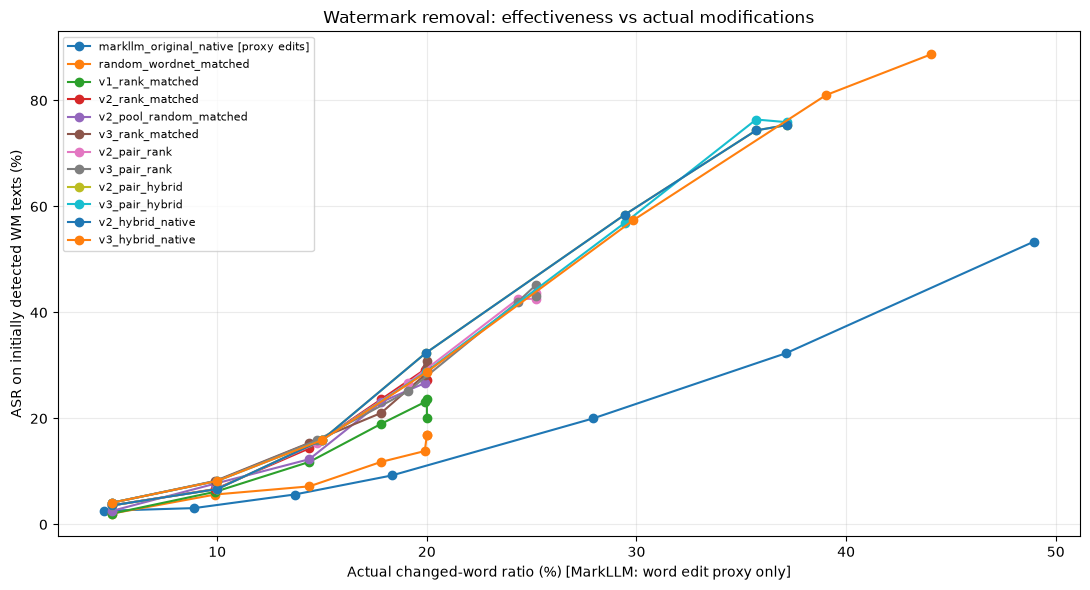

Descriptive AUC: only comparable within the same matched group


,split_id,support,comparison_group,method,normalized_auc_asr,min_actual_edit_ratio,max_actual_edit_ratio
0,100,1,main_matched,random_wordnet_matched,0.0408,0.0501,0.2012
1,100,1,main_matched,v1_rank_matched,0.0889,0.0501,0.2012
2,100,1,main_matched,v2_rank_matched,0.1171,0.0501,0.2012
3,100,1,main_matched,v2_pool_random_matched,0.0996,0.0501,0.2012
4,100,1,main_matched,v2_synonym_guided_matched,0.1304,0.0501,0.2012
5,100,1,main_matched,v3_rank_matched,0.1073,0.0501,0.2012
6,100,1,main_matched,v3_pool_random_matched,0.1003,0.0501,0.2012
7,100,1,v2v3_pair_rank,v2_pair_rank,0.1826,0.0501,0.2546
8,100,1,v2v3_pair_rank,v3_pair_rank,0.1721,0.0501,0.2546
9,100,1,v2v3_pair_hybrid,v2_pair_hybrid,0.3124,0.0501,0.3688


Primary predeclared paired contrasts at nominal budget 0.2


,support,comparison,method_a,method_b,n,asr_a,asr_b,difference_pp,ci_diff_low_pp,ci_diff_high_pp,a_only,b_only,discordant,p_raw,p_holm,p_holm_lt_0_05
0,1,v2_vs_random_global,v2_rank_matched,random_wordnet_matched,195,0.23590,0.11795,11.79487,6.15385,17.43590,29,6,35,0.00012,0.00245,True
1,1,v2_rank_vs_pool,v2_rank_matched,v2_pool_random_matched,195,0.23590,0.23077,0.51282,-4.10256,5.12821,11,10,21,1.00000,1.00000,False
2,1,v3_vs_v2,v3_rank_matched,v2_rank_matched,195,0.21026,0.23590,-2.56410,-7.69231,2.56410,11,16,27,0.44207,1.00000,False
3,1,v3_vs_v2_pairwise,v3_pair_rank,v2_pair_rank,195,0.25128,0.26667,-1.53846,-6.66667,3.58974,13,16,29,0.71107,1.00000,False
4,1,v3_hybrid_vs_v2_hybrid_pairwise,v3_pair_hybrid,v2_pair_hybrid,195,0.28718,0.32308,-3.58974,-9.23077,2.05128,13,20,33,0.29621,1.00000,False
5,1,v3_rank_vs_v3_pool,v3_rank_matched,v3_pool_random_matched,195,0.21026,0.15385,5.64103,0.51282,10.78205,20,9,29,0.06143,1.00000,False
6,1,guided_synonym_vs_random,v2_synonym_guided_matched,v2_rank_matched,195,0.24615,0.23590,1.02564,-1.53846,3.58974,4,2,6,0.68750,1.00000,False
7,1,v1_common_vs_random,v1_common_rank,random_common_pool,195,0.08205,0.09231,-1.02564,-2.56410,0.00000,0,2,2,0.50000,1.00000,False
8,1,v2_common_vs_random,v2_common_rank,random_common_pool,195,0.08205,0.09231,-1.02564,-3.07692,1.02564,1,3,4,0.62500,1.00000,False
9,1,v3_common_vs_random,v3_common_rank,random_common_pool,195,0.07692,0.09231,-1.53846,-4.10256,0.51282,1,4,5,0.37500,1.00000,False


In [26]:
all_rows=[]
for split_id,_,test_ids in ALL_RUN_SPLITS:
    for support in SUPPORTS:
        for ratio in RATIOS:
            path=checkpoint_file(split_id,support,ratio)
            if not path.exists(): raise FileNotFoundError(f'Missing checkpoint: {path}')
            rows=read_jsonl(path)
            validate_rows(rows,split_id,support,ratio,test_ids)
            all_rows.extend(rows)
raw=pd.DataFrame(all_rows)
assert not raw.duplicated(['split_id','support','ratio','idx','method']).any()
raw.to_csv(OUT_DIR/'observations.csv',index=False)

summary=[]
for (split,s,r,method),g in raw.groupby(['split_id','support','ratio','method'],sort=True):
    eligible=g[g.original_detected]
    assert len(eligible)>0,'No originally detected test texts; ASR undefined'
    successes=int((eligible.detected==False).sum())
    ci=binomtest(successes,len(eligible)).proportion_ci(method='wilson')
    summary.append({'split_id':split,'support':int(s),'ratio':r,'method':method,
       'eligible_n':len(eligible),'successes':successes,'asr':successes/len(eligible),
       'asr_ci_low':ci.low,'asr_ci_high':ci.high,
       'actual_edit_ratio':g.n_replaced.sum()/g.n_words.sum(),
       'edit_ratio_on_eligible':eligible.n_replaced.sum()/eligible.n_words.sum(),
       'mean_edits':g.n_replaced.mean(),
       'mean_coverage_v1':g.n_eligible_v1.sum()/g.n_words.sum(),
       'mean_coverage_v2':g.n_eligible_v2.sum()/g.n_words.sum(),
       'mean_coverage_v3':g.n_eligible_v3.sum()/g.n_words.sum(),
       'fraction_below_target':(g.n_replaced<g.target).mean(),
       'n_guided_fraction':g.n_guided.sum()/max(1,g.n_replaced.sum()),
       'count_type':g.count_type.iloc[0]})
summary_df=pd.DataFrame(summary).sort_values(['split_id','support','ratio','method'])
summary_df.to_csv(OUT_DIR/'summary_by_split.csv',index=False)

# Dataset-level error analysis: never assume identical ASR across WaterBench sources.
dataset_summary=[]
for (split,s,r,method,dataset),grp in raw.groupby(['split_id','support','ratio','method','dataset'],sort=True):
    eligible=grp[grp.original_detected]
    dataset_summary.append({'split_id':split,'support':s,'ratio':r,'method':method,'dataset':dataset,
                            'eligible_n':len(eligible),
                            'asr':float((eligible.detected==False).mean()) if len(eligible) else np.nan,
                            'actual_edit_ratio':grp.n_replaced.sum()/max(1,grp.n_words.sum())})
dataset_df=pd.DataFrame(dataset_summary)
dataset_df.to_csv(OUT_DIR/'summary_by_dataset.csv',index=False)
print('ASR summary:')
display(summary_df[['split_id','support','ratio','method','eligible_n','asr','actual_edit_ratio','fraction_below_target']].round(4).head(50))

# Separate descriptive aggregation: mean over splits, no pooled 95% CI or pooled p-values.
stability = (summary_df.groupby(['support','ratio','method'],as_index=False)
             .agg(mean_asr=('asr','mean'),sd_asr=('asr','std'),n_splits=('asr','size'),
                  mean_actual_edit_ratio=('actual_edit_ratio','mean')))
stability.to_csv(OUT_DIR/'stability_across_splits_descriptive.csv',index=False)

# Native/hybrid vs matched plot: y=ASR, x=actual changed-word ratio (proxy for MarkLLM).
import matplotlib.pyplot as plt
reference_split=ALL_RUN_SPLITS[0][0]
ref=summary_df[(summary_df.split_id==reference_split)&(summary_df.support==SUPPORTS[0])]
fig,ax=plt.subplots(figsize=(11,6))
plot_names=['markllm_original_native','random_wordnet_matched','v1_rank_matched',
            'v2_rank_matched','v2_pool_random_matched','v3_rank_matched',
            'v2_pair_rank','v3_pair_rank','v2_pair_hybrid','v3_pair_hybrid',
            'v2_hybrid_native','v3_hybrid_native']
for method in plot_names:
    part=ref[ref.method==method].sort_values('actual_edit_ratio')
    if not part.empty:
        label=method + (' [proxy edits]' if method=='markllm_original_native' else '')
        ax.plot(100*part.actual_edit_ratio,100*part.asr,marker='o',label=label)
ax.set(xlabel='Actual changed-word ratio (%) [MarkLLM: word edit proxy only]',
       ylabel='ASR on initially detected WM texts (%)',
       title='Watermark removal: effectiveness vs actual modifications')
ax.grid(alpha=.25);ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(OUT_DIR/'asr_vs_actual_edits.png',dpi=170)
plt.show()

# Descriptive normalized AUC within each matched group; this does not replace primary paired inference.
auc_rows=[]
for (split,support),part in summary_df.groupby(['split_id','support']):
    for group_name,methods in [('main_matched',MAIN_MATCHED),('v2v3_pair_rank',PAIR_MATCHED[:2]),
                                   ('v2v3_pair_hybrid',PAIR_MATCHED[2:]),('common_matched',COMMON_MATCHED)]:
        curves=[]
        for method in methods:
            g=part[part.method==method].groupby('actual_edit_ratio',as_index=False)['asr'].mean().sort_values('actual_edit_ratio')
            curves.append((method,g))
        # All x-values are theoretically identical here, since per-prompt edited-word counts are equal.
        assert all(np.allclose(curves[0][1].actual_edit_ratio.to_numpy(),v.actual_edit_ratio.to_numpy())
                   for _,v in curves), 'Matched x-axis differs unexpectedly'
        for method,g in curves:
            x=g.actual_edit_ratio.to_numpy(); y=g.asr.to_numpy()
            auc=(float(trapezoid(y,x)/(x[-1]-x[0])) if len(x)>1 and x[-1]>x[0] else np.nan)
            auc_rows.append({'split_id':split,'support':support,'comparison_group':group_name,
                             'method':method,'normalized_auc_asr':auc,
                             'min_actual_edit_ratio':x[0] if len(x) else np.nan,
                             'max_actual_edit_ratio':x[-1] if len(x) else np.nan})
auc_df=pd.DataFrame(auc_rows)
auc_df.to_csv(OUT_DIR/'matched_auc_descriptive.csv',index=False)
print('Descriptive AUC: only comparable within the same matched group')
display(auc_df.head(20).round(4))

def holm_adjust(p_values):
    n=len(p_values); indices=sorted(range(n),key=lambda i:p_values[i]);out=[None]*n;cur=0.
    for rank,i in enumerate(indices):
        cur=max(cur,min(1.,(n-rank)*float(p_values[i])))
        out[i]=cur
    return out

def paired_bootstrap_interval(a,b,n_boot=4000,seed=2026):
    a=np.asarray(a,dtype=float);b=np.asarray(b,dtype=float)
    assert len(a)==len(b)
    rng=np.random.default_rng(seed)
    sample_diffs=[]
    for _ in range(n_boot):
        sample=rng.integers(0,len(a),len(a))
        sample_diffs.append(float((a[sample]-b[sample]).mean()))
    return tuple(np.quantile(sample_diffs,[.025,.975]))

# Pre-registered contrasts: all compare matched word counts per text.
PRIMARY_CONTRASTS=[
    ('v2_vs_random_global','v2_rank_matched','random_wordnet_matched'),
    ('v2_rank_vs_pool','v2_rank_matched','v2_pool_random_matched'),
    ('v3_vs_v2','v3_rank_matched','v2_rank_matched'),
    ('v3_vs_v2_pairwise','v3_pair_rank','v2_pair_rank'),
    ('v3_hybrid_vs_v2_hybrid_pairwise','v3_pair_hybrid','v2_pair_hybrid'),
    ('v3_rank_vs_v3_pool','v3_rank_matched','v3_pool_random_matched'),
    ('guided_synonym_vs_random','v2_synonym_guided_matched','v2_rank_matched'),
    ('v1_common_vs_random','v1_common_rank','random_common_pool'),
    ('v2_common_vs_random','v2_common_rank','random_common_pool'),
    ('v3_common_vs_random','v3_common_rank','random_common_pool'),
]

def exact_mcnemar(sub,a,b):
    merged=(sub[sub.method==a][['idx','detected','n_replaced']].rename(columns={'detected':'det_a','n_replaced':'na'})
            .merge(sub[sub.method==b][['idx','detected','n_replaced']].rename(columns={'detected':'det_b','n_replaced':'nb'}),on='idx',validate='one_to_one'))
    assert len(merged)==len(sub[sub.method==a])==len(sub[sub.method==b])
    assert (merged.na==merged.nb).all(),f'NOT matched: {a}, {b}'
    sa=(merged.det_a==False).astype(int).to_numpy()
    sb=(merged.det_b==False).astype(int).to_numpy()
    a_only=int(((sa==1)&(sb==0)).sum());b_only=int(((sa==0)&(sb==1)).sum())
    discordant=a_only+b_only
    p=binomtest(a_only,discordant,p=.5).pvalue if discordant else 1.
    low,high=paired_bootstrap_interval(sa,sb)
    return {'n':len(sa),'asr_a':float(sa.mean()),'asr_b':float(sb.mean()),
            'difference_pp':100*float(sa.mean()-sb.mean()),
            'ci_diff_low_pp':100*low,'ci_diff_high_pp':100*high,
            'a_only':a_only,'b_only':b_only,'discordant':discordant,'p_raw':p}

is_reference=raw[(raw.split_id==reference_split)&(raw.ratio==PRIMARY_RATIO)&raw.original_detected]
contrasts=[]
for support in SUPPORTS:
    sub=is_reference[is_reference.support==support]
    for label,a,b in PRIMARY_CONTRASTS:
        stats_pair=exact_mcnemar(sub,a,b)
        contrasts.append({'support':support,'comparison':label,'method_a':a,'method_b':b,**stats_pair})
# Support ablation: equal actual edits per prompt across s=1/2, compare only if both present.
if 1 in SUPPORTS and 2 in SUPPORTS:
    m='v2_rank_matched'
    sub1=is_reference[(is_reference.support==1)&(is_reference.method==m)]
    sub2=is_reference[(is_reference.support==2)&(is_reference.method==m)]
    joined=sub1[['idx','detected','n_replaced']].merge(sub2[['idx','detected','n_replaced']],on='idx',suffixes=('_1','_2'))
    assert (joined.n_replaced_1==joined.n_replaced_2).all()
    x=(joined.detected_1==False).astype(int).to_numpy();y=(joined.detected_2==False).astype(int).to_numpy()
    a_only=int(((x==1)&(y==0)).sum());b_only=int(((x==0)&(y==1)).sum())
    dd=a_only+b_only;lo,hi=paired_bootstrap_interval(x,y)
    contrasts.append({'support':'1_vs_2','comparison':'min_support_1_vs_2_equal_edits',
        'method_a':'v2_support_1','method_b':'v2_support_2','n':len(joined),
        'asr_a':float(x.mean()),'asr_b':float(y.mean()),
        'difference_pp':100*float(x.mean()-y.mean()),
        'ci_diff_low_pp':100*lo,'ci_diff_high_pp':100*hi,
        'a_only':a_only,'b_only':b_only,'discordant':dd,
        'p_raw':binomtest(a_only,dd,p=.5).pvalue if dd else 1.})

if contrasts:
    p_holm=holm_adjust([item['p_raw'] for item in contrasts])
    for row,p in zip(contrasts,p_holm):
        row['p_holm']=p;row['p_holm_lt_0_05']=(p<0.05)
contrast_df=pd.DataFrame(contrasts)
contrast_df.to_csv(OUT_DIR/'paired_mcnemar_holm.csv',index=False)
print('Primary predeclared paired contrasts at nominal budget',PRIMARY_RATIO)
display(contrast_df.round(5))

## 8 bis — Classement et diagnostic du **pourquoi** (V2)

Les résultats de 30 textes ne servent qu'à déboguer. Pour interpréter les gains, lisez **ensemble** les tableaux `rankings_matched_descriptive.csv`, `ablation_differences_descriptive.csv`, `position_overlap_and_coverage.csv` et `discordant_examples.csv`.

Le rang AUC est calculé **au sein de chaque famille à budget effectivement égal**. AUC V2/V3 pairwise ≠ AUC global matched si la plage de budget diffère. Les écarts moyens sur les 10 splits ne sont **pas** des tests significatifs : les splits 400/200 réutilisent les mêmes prompts.

Le registre `replacement_pairs` décrit quelles positions ont été sélectionnées et quels synonymes ont été choisis. **On ne prétend pas** que des scores statistiques démontrent à eux seuls un mécanisme causal ; l'ablation sert à éprouver cette interprétation.

In [27]:
# 1. Classement AUC descriptif (groupe, support, split comparables uniquement)
rankings=(auc_df.groupby(['support','comparison_group','method'],as_index=False)
          .agg(mean_normalized_auc=('normalized_auc_asr','mean'),
               sd_across_splits=('normalized_auc_asr','std'),
               n_splits=('normalized_auc_asr','size'),
               mean_budget_min=('min_actual_edit_ratio','mean'),
               mean_budget_max=('max_actual_edit_ratio','mean')))
rankings['rank_within_group']=rankings.groupby(['support','comparison_group'])['mean_normalized_auc'].rank(ascending=False,method='min').astype(int)
rankings=rankings.sort_values(['support','comparison_group','rank_within_group'])
rankings.to_csv(OUT_DIR/'rankings_matched_descriptive.csv',index=False)
print('Classement AUC : uniquement au sein du même comparison_group et support')
display(rankings.round(4))

# 2. Les ablations à budget principal avec effet moyen sur les splits.
#    Les paires sont appariées PAR TEXTE et PAR SPLIT. Aucun empilement n'est utilisé
#    pour estimer des p-values ou intervalles de confiance.
ablations=[
 ('V1 vs random global','v1_rank_matched','random_wordnet_matched'),
 ('Pool V2 vs random global','v2_pool_random_matched','random_wordnet_matched'),
 ('Ranking V2 vs random pool V2','v2_rank_matched','v2_pool_random_matched'),
 ('Synonym choice V2 vs random synonym','v2_synonym_guided_matched','v2_rank_matched'),
 ('Pool V3 vs random global','v3_pool_random_matched','random_wordnet_matched'),
 ('Ranking V3 vs random pool V3','v3_rank_matched','v3_pool_random_matched'),
 ('V3 vs V2 global matched','v3_rank_matched','v2_rank_matched'),
 ('V3 vs V2 pairwise','v3_pair_rank','v2_pair_rank'),
 ('V3 Hybrid vs V2 Hybrid pairwise','v3_pair_hybrid','v2_pair_hybrid'),
 ('V1 ranking vs random common pool','v1_common_rank','random_common_pool'),
 ('V2 ranking vs random common pool','v2_common_rank','random_common_pool'),
 ('V3 ranking vs random common pool','v3_common_rank','random_common_pool'),
]
subset=raw[(raw.ratio==PRIMARY_RATIO)&raw.original_detected]
abl_rows=[]
for (split,support),g in subset.groupby(['split_id','support']):
    pivot=g.pivot(index='idx',columns='method',values='detected')
    counts=g.pivot(index='idx',columns='method',values='n_replaced')
    for label,a,b in ablations:
        assert (counts[a]==counts[b]).all(), f'Unmatched: {label}'
        asr_a=(pivot[a]==False).mean();asr_b=(pivot[b]==False).mean()
        abl_rows.append({'split_id':split,'support':support,'ablation':label,
                         'method_a':a,'method_b':b,'n':len(pivot),
                         'difference_pp':100*(asr_a-asr_b),
                         'asr_a':asr_a,'asr_b':asr_b,
                         'mean_actual_edits':g[g.method==a].actual_edit_ratio.mean()})
abl_split=pd.DataFrame(abl_rows)
abl_split.to_csv(OUT_DIR/'ablation_differences_by_split.csv',index=False)
abl_agg=(abl_split.groupby(['support','ablation','method_a','method_b'],as_index=False)
         .agg(mean_difference_pp=('difference_pp','mean'),
              sd_split_pp=('difference_pp','std'),
              n_splits=('difference_pp','size'),
              mean_asr_a=('asr_a','mean'), mean_asr_b=('asr_b','mean'),
              mean_actual_edits=('mean_actual_edits','mean')))
abl_agg.to_csv(OUT_DIR/'ablation_differences_descriptive.csv',index=False)
print('Ablations — descriptif, différence positive = avantage méthode A')
display(abl_agg.round(3))

Classement AUC : uniquement au sein du même comparison_group et support


,support,comparison_group,method,mean_normalized_auc,sd_across_splits,n_splits,mean_budget_min,mean_budget_max,rank_within_group
1,1,common_matched,v1_common_rank,0.0551,0.0112,10,0.0489,0.1037,1
2,1,common_matched,v2_common_rank,0.0548,0.0133,10,0.0489,0.1037,2
3,1,common_matched,v3_common_rank,0.0529,0.0109,10,0.0489,0.1037,3
0,1,common_matched,random_common_pool,0.0478,0.0116,10,0.0489,0.1037,4
8,1,main_matched,v2_synonym_guided_matched,0.1498,0.0168,10,0.0500,0.2069,1
7,1,main_matched,v2_rank_matched,0.1426,0.0165,10,0.0500,0.2069,2
10,1,main_matched,v3_rank_matched,0.1396,0.0221,10,0.0500,0.2069,3
6,1,main_matched,v2_pool_random_matched,0.1264,0.0199,10,0.0500,0.2069,4
9,1,main_matched,v3_pool_random_matched,0.1152,0.0149,10,0.0500,0.2069,5
5,1,main_matched,v1_rank_matched,0.1126,0.0168,10,0.0500,0.2069,6


Ablations — descriptif, différence positive = avantage méthode A


,support,ablation,method_a,method_b,mean_difference_pp,sd_split_pp,n_splits,mean_asr_a,mean_asr_b,mean_actual_edits
0,1,Pool V2 vs random global,v2_pool_random_matched,random_wordnet_matched,9.379,1.735,10,0.200,0.106,0.178
1,1,Pool V3 vs random global,v3_pool_random_matched,random_wordnet_matched,7.928,2.568,10,0.185,0.106,0.178
2,1,Ranking V2 vs random pool V2,v2_rank_matched,v2_pool_random_matched,3.816,2.176,10,0.238,0.200,0.178
3,1,Ranking V3 vs random pool V3,v3_rank_matched,v3_pool_random_matched,4.037,3.375,10,0.225,0.185,0.178
4,1,Synonym choice V2 vs random synonym,v2_synonym_guided_matched,v2_rank_matched,1.339,1.006,10,0.251,0.238,0.178
5,1,V1 ranking vs random common pool,v1_common_rank,random_common_pool,0.255,1.173,10,0.083,0.080,0.102
6,1,V1 vs random global,v1_rank_matched,random_wordnet_matched,7.630,1.780,10,0.182,0.106,0.178
7,1,V2 ranking vs random common pool,v2_common_rank,random_common_pool,0.618,1.107,10,0.087,0.080,0.102
8,1,V3 Hybrid vs V2 Hybrid pairwise,v3_pair_hybrid,v2_pair_hybrid,-0.294,3.024,10,0.284,0.287,0.200
9,1,V3 ranking vs random common pool,v3_common_rank,random_common_pool,0.260,1.120,10,0.083,0.080,0.102


In [28]:
# 3. Couverture, chevauchement et désaccords des méthodes : sur le split de référence.
# Les positions sont sauvegardées en clair dans les checkpoints v2 pour auditer
# les stratégies. On utilise seulement des textes détectés avant attaque.
refdata=subset[subset.split_id==reference_split]
coverage=[];discordant=[]
for (support,idx), g in refdata.groupby(['support','idx']):
    by={r.method:r for r in g.itertuples(index=False)}
    if 'v2_pair_rank' not in by or 'v3_pair_rank' not in by: continue
    a=by['v2_pair_rank'];b=by['v3_pair_rank']
    ia=set(a.selected_indices);ib=set(b.selected_indices)
    assert a.n_replaced==b.n_replaced
    union=len(ia|ib)
    coverage.append({'support':support,'idx':idx,'dataset':a.dataset,
                     'n_words':a.n_words,'paired_edits':a.n_replaced,
                     'eligible_v1':a.n_eligible_v1,'eligible_v2':a.n_eligible_v2,
                     'eligible_v3':a.n_eligible_v3,
                     'eligible_union':a.n_eligible_union,
                     'n_shared_selected':len(ia&ib),
                     'jaccard_selected':len(ia&ib)/union if union else 1.,
                     'asr_v2':not bool(a.detected),'asr_v3':not bool(b.detected),
                     'p_value_v2':a.p_value,'p_value_v3':b.p_value})
    if bool(a.detected)!=bool(b.detected):
        discordant.append({'support':support,'idx':idx,'dataset':a.dataset,
                           'winner':'V3' if not b.detected else 'V2',
                           'n_replaced':a.n_replaced,
                           'v2_p_value':a.p_value,'v3_p_value':b.p_value,
                           'v2_replacements':json.dumps(a.replacement_pairs,ensure_ascii=False),
                           'v3_replacements':json.dumps(b.replacement_pairs,ensure_ascii=False)})
coverage_df_v2=pd.DataFrame(coverage)
coverage_df_v2.to_csv(OUT_DIR/'position_overlap_and_coverage.csv',index=False)
discordant_df=pd.DataFrame(discordant,columns=['support','idx','dataset','winner','n_replaced','v2_p_value','v3_p_value','v2_replacements','v3_replacements'])
discordant_df.to_csv(OUT_DIR/'discordant_examples.csv',index=False)
print('Analyse des positions par support')
display(coverage_df_v2.groupby('support').agg(n=('idx','size'),
  mean_shared_positions=('n_shared_selected','mean'),
  mean_selected_jaccard=('jaccard_selected','mean'),
  avg_eligible_v2=('eligible_v2','mean'),avg_eligible_v3=('eligible_v3','mean')).round(3))
print('Exemples V2/V3 avec résultats différents :',len(discordant_df))
display(discordant_df.head(12))

Analyse des positions par support


,n,mean_shared_positions,mean_selected_jaccard,avg_eligible_v2,avg_eligible_v3
support,,,,,
1,195,24.267,0.489,48.862,64.600
2,195,23.451,0.495,42.364,60.128


Exemples V2/V3 avec résultats différents : 53


,support,idx,dataset,winner,n_replaced,v2_p_value,v3_p_value,v2_replacements,v3_replacements
0,1,1,2-1_longform_qa,V3,49,0.009615,0.028679,"[{""word_index"": 25, ""original"": ""tell"", ""repla...","[{""word_index"": 25, ""original"": ""tell"", ""repla..."
1,1,8,2-1_longform_qa,V3,52,0.004058,0.012509,"[{""word_index"": 208, ""original"": ""not"", ""repla...","[{""word_index"": 208, ""original"": ""not"", ""repla..."
2,1,11,2-1_longform_qa,V2,42,0.027188,0.000043,"[{""word_index"": 140, ""original"": ""share"", ""rep...","[{""word_index"": 140, ""original"": ""share"", ""rep..."
3,1,22,2-1_longform_qa,V2,36,0.010317,0.008169,"[{""word_index"": 131, ""original"": ""not"", ""repla...","[{""word_index"": 19, ""original"": ""used"", ""repla..."
4,1,74,2-1_longform_qa,V2,46,0.014509,0.000675,"[{""word_index"": 153, ""original"": ""ukraine"", ""r...","[{""word_index"": 151, ""original"": ""friends"", ""r..."
5,1,107,2-1_longform_qa,V3,19,0.000294,0.047507,"[{""word_index"": 88, ""original"": ""different"", ""...","[{""word_index"": 88, ""original"": ""different"", ""..."
6,1,114,2-1_longform_qa,V3,34,0.002130,0.036958,"[{""word_index"": 161, ""original"": ""capture"", ""r...","[{""word_index"": 161, ""original"": ""capture"", ""r..."
7,1,154,2-1_longform_qa,V2,50,0.042655,0.004825,"[{""word_index"": 243, ""original"": ""be"", ""replac...","[{""word_index"": 96, ""original"": ""very"", ""repla..."
8,1,173,2-1_longform_qa,V3,36,0.001131,0.027642,"[{""word_index"": 1, ""original"": ""in"", ""replacem...","[{""word_index"": 140, ""original"": ""in"", ""replac..."
9,1,181,2-1_longform_qa,V2,35,0.010332,0.002750,"[{""word_index"": 133, ""original"": ""up"", ""replac...","[{""word_index"": 98, ""original"": ""people"", ""rep..."


### Interprétation recommandée

- **Pool** : si random dans le pool V2 gagne face à random WordNet global, le filtre d'éligibilité explique une part du gain.
- **Ranking** : si V2 rank gagne face au hasard **dans le même pool**, le classement ajoute une amélioration.
- **Synonyme** : comparer exactement les mêmes positions avec synonyme choisi au hasard vs synonyme guidé.
- **V2 vs V3** : privilégier le duel pairwise avec le même nombre exact de substitutions **par texte** ; le pool commun isole plus strictement le classement mais peut saturer avant 10 %.
- **Hybrides** : comparer le duel hybride pairwise, mais vérifier si les ordres des positions se distinguent réellement à budget commun ; la performance native résulte également de leur couverture plus large.
- **Statistiques** : McNemar + Holm du split 42 donnent une inférence exploratoire sur ce split, pas une preuve indépendante. Prévoir un holdout entièrement nouveau après sélection du protocole.
- **Qualité** : avant de déclarer un gagnant, mesurer les altérations grammaticales et sémantiques. Une ASR élevée sur des textes dénaturés n'est pas suffisante.

## 9 — Contrôles de conservation du sens (optionnels mais requis pour une revendication forte)

Le taux de substitutions ne garantit pas la **qualité** : WordNet peut produire des phrases grammaticalement mauvaises ou des changements de sens. Cette étape calcule une similarité entre embeddings de phrases (`all-MiniLM-L6-v2`), utile comme *proxy*, mais **pas** comme preuve de fidélité sémantique. Le notebook exporte aussi un échantillon **aveugle** pour évaluation humaine (sens / grammaticalité). Ne prétendez pas à une meilleure attaque « à sens conservé » sans cette vérification.

Pour éviter d'installer des dépendances coûteuses pendant le pilote : `SEMANTIC_EVAL=False` initialement ; lorsque les sorties sont complètes, activer le calcul ici. Pour le final, une évaluation exhaustive ou un échantillon **pré-déclaré et équilibré** est préférable.

In [29]:
if not STORE_ATTACKED_TEXT:
    print('No attacked text saved; rerun with STORE_ATTACKED_TEXT=True and NEW output directory for semantic evaluation.')
else:
    # Balanced blinded sample: deterministic, method x nominal budget, on originally detected examples.
    focus=raw[(raw.ratio==PRIMARY_RATIO)&raw.original_detected]
    rng=np.random.default_rng(1124)
    sample=[];identity=[]
    for (split,support,method),grp in focus.groupby(['split_id','support','method'],sort=True):
        g=grp.sort_values('idx')
        rng_idx=rng.choice(len(g),size=min(10,len(g)),replace=False)
        for z in sorted(rng_idx):
            rec=g.iloc[int(z)]
            blind_id='T'+text_hash(f'{split}/{support}/{method}/{rec.idx}/{PRIMARY_RATIO}')[:15]
            sample.append({'blind_id':blind_id,'dataset':rec.dataset,'original':rec.original,
                           'attacked':rec.attacked,'semantic_preserved_0_1':'',
                           'grammar_preserved_0_1':'','rater_notes':''})
            identity.append({'blind_id':blind_id,'method':method,'split_id':split,
                             'support':support,'idx':int(rec.idx)})
    pd.DataFrame(sample).sort_values('blind_id').to_csv(OUT_DIR/'human_eval_blinded.csv',index=False)
    pd.DataFrame(identity).to_csv(OUT_DIR/'human_eval_blinded_key.csv',index=False)
    print('Blinded manual-evaluation sample exported:',len(sample),'examples')

    if SEMANTIC_EVAL:
        from sentence_transformers import SentenceTransformer
        model=SentenceTransformer(SEMANTIC_MODEL)
        # Deterministic selection of text pairs; if subset, this is exploratory (NOT whole-benchmark quality).
        rows=raw[raw.original_detected].copy().sort_values(['split_id','support','ratio','method','idx'])
        if SEMANTIC_MAX_PAIRS is not None and len(rows)>SEMANTIC_MAX_PAIRS:
            rows=rows.sample(n=SEMANTIC_MAX_PAIRS,random_state=2026).sort_values(['split_id','support','ratio','method','idx'])
        originals=rows.original.tolist(); attacked=rows.attacked.tolist()
        E0=model.encode(originals,batch_size=32,normalize_embeddings=True,show_progress_bar=True)
        E1=model.encode(attacked,batch_size=32,normalize_embeddings=True,show_progress_bar=True)
        rows['embedding_cosine']=(E0*E1).sum(axis=1)
        rows[['split_id','idx','support','ratio','method','embedding_cosine']].to_csv(
            OUT_DIR/'semantic_similarity_per_sample.csv',index=False)
        print('Cosine similarity computed on',len(rows),'pairs (not a guarantee of semantic fidelity).')
        display(rows.groupby('method')['embedding_cosine'].agg(['mean','median','count']).round(4))
    else:
        print('SEMANTIC_EVAL=False: semantic quality has NOT been measured. Enable before drawing semantic conclusions.')

Blinded manual-evaluation sample exported: 3500 examples
SEMANTIC_EVAL=False: semantic quality has NOT been measured. Enable before drawing semantic conclusions.


## 10 — Manifest, vérification de complétude, sauvegarde et synthèse

Tous les fichiers ci-dessous sont dans `OUT_DIR`. Les résultats sont sauvegardés en continu ; si Colab est utilisé, **vérifier qu'`OUT_DIR` pointe vers Google Drive avant de lancer**. Les sorties de ce notebook n'ont pas été calculées ici : elles seront obtenues dans votre runtime disposant du dépôt, des données et du GPU.

In [30]:
expected=[checkpoint_file(s,support,ratio) for s,_,_ in ALL_RUN_SPLITS for support in SUPPORTS for ratio in RATIOS]
missing=[str(p) for p in expected if not p.exists()]
MANIFEST={
    'run_mode':RUN_MODE, 'pilot':FAST_PILOT, 'benchmark_version':'v2_mechanism',
    'split_ids':[s for s,_,_ in ALL_RUN_SPLITS],
    'input_sha256':INPUT_HASHES, 'protocol':PROTOCOL,
    'completed_checkpoints':len(expected)-len(missing),
    'expected_checkpoints':len(expected), 'missing':missing,
    'n_records':len(raw),'n_detector_cache':len(DETECTION_CACHE),
    'out_dir':str(OUT_DIR), 'semantic_evaluation_enabled':SEMANTIC_EVAL,
    'warnings':[
        'Baseline MarkLLM uses its own editor: difflib word edit count is only a proxy.',
        'Matched equal counts do not imply equal candidate pools; use common-pool contrasts.',
        'Hybrids are unmatched on real edit counts and must be reported descriptively.',
        'Development splits overlap: never pool test observations for statistical inference.',
        'Token bigrams use post-hoc LLaDA tokenizer, not diffusion trajectory.',
        'WordNet can alter semantics/grammar; automated embedding cosine is only a proxy.',
        'Pilot results are only for validating the pipeline; not final science.',
        'V2/V3 pairwise comparisons use identical edit counts but different candidate pools.',
    ],
}
(OUT_DIR/'manifest.json').write_text(json.dumps(MANIFEST,indent=2,ensure_ascii=False),encoding='utf-8')
assert not missing
if RUN_MODE == 'development' and FREEZE_PROTOCOL_AFTER_DEVELOPMENT:
    if FAST_PILOT:
        raise ValueError('Cannot freeze parameters on a pilot. Run FAST_PILOT=False and inspect DEVELOPMENT results first.')
    if PROTOCOL_LOCK.exists():
        assert json.loads(PROTOCOL_LOCK.read_text(encoding='utf-8')) == PROTOCOL, 'Existing protocol freeze differs.'
    else:
        PROTOCOL_LOCK.write_text(json.dumps(PROTOCOL,indent=2,ensure_ascii=False),encoding='utf-8')
        print('Final evaluation protocol FROZEN:',PROTOCOL_LOCK)
print('CHECKPOINTS OK:',len(expected),'| outputs:',OUT_DIR)
if RUN_MODE=='development':
    print('EXPLORATORY ONLY: freeze settings after deciding, then evaluate an independent holdout.')
else:
    print('FINAL MODE: independent prompt disjointness checked and frozen protocol validated.')
print('Main files: observations.csv, summary_by_split.csv, paired_mcnemar_holm.csv, asr_vs_actual_edits.png')
print('Extra files: rankings_matched_descriptive.csv, ablation_differences_descriptive.csv, position_overlap_and_coverage.csv, discordant_examples.csv')

# Optional local .zip artifact; default keeps checkpoints natively on persistent folder.
MAKE_ZIP=False
if MAKE_ZIP:
    output=shutil.make_archive(str(OUT_DIR),'zip',root_dir=OUT_DIR)
    print('Bundle ready:',output)
    # in Google Colab if desired:
    # from google.colab import files
    # files.download(output)

CHECKPOINTS OK: 140 | outputs: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/fair_comparison_benchmark_v2/development_full
EXPLORATORY ONLY: freeze settings after deciding, then evaluate an independent holdout.
Main files: observations.csv, summary_by_split.csv, paired_mcnemar_holm.csv, asr_vs_actual_edits.png
Extra files: rankings_matched_descriptive.csv, ablation_differences_descriptive.csv, position_overlap_and_coverage.csv, discordant_examples.csv
